# samscheduler example

This notebook inspects the package's static target catalog, creates a schedule for a reproducible observing night, and plots target airmasses with scheduled exposures.

Install the project dependencies from the repository root with `python -m pip install -r requirements.txt` before running the code cells.

In [1]:
from datetime import date
from pathlib import Path
import sys

# Find the repository root so the src-layout package also imports when the
# notebook kernel starts in nb/ rather than the project root.
project_root = Path.cwd().resolve()
while not (project_root / "pyproject.toml").is_file():
    if project_root.parent == project_root:
        raise RuntimeError("Run this notebook from within the samscheduler repository")
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from samscheduler.catalog import DEFAULT_TARGETS, OBSERVATORY
from samscheduler.scheduler import Scheduler

## Static catalog

Coordinates are ICRS degrees. Each example target includes one exposure in each of the UBVRI filters.

In [2]:
catalog_rows = [
    {
        "target": target.name,
        "RA (deg)": target.ra_deg,
        "Dec (deg)": target.dec_deg,
        "priority": target.priority,
        "exposures (filter: seconds)": ", ".join(
            f"{exposure.filter.value}: {exposure.seconds}"
            for exposure in target.exposures
        ),
    }
    for target in DEFAULT_TARGETS
]
catalog_rows
print(f"Observatory: lat={OBSERVATORY.lat.deg:.4f}°, lon={OBSERVATORY.lon.deg:.4f}°")

Observatory: lat=32.4167°, lon=-110.7344°


## Run the scheduler

`observing_date` is the local calendar date on which the observing window begins. This example uses a fixed date so the schedule can be reproduced.

In [6]:
scheduler = Scheduler(
    targets=DEFAULT_TARGETS,
    observing_date=date(2025, 6, 21),
    location=OBSERVATORY,
)
schedule = scheduler.run()
print(f"Scheduled {len(schedule)} exposure(s)")
[
    {
        "target": entry.target.name,
        "exposures": ", ".join(
            f"{exposure.filter.value}: {exposure.seconds}" for exposure in entry.exposures
        ),  
        "start (UTC)": entry.start_utc.isoformat(),
        "end (UTC)": entry.end_utc.isoformat(),
        "airmass": round(entry.airmass, 3),
    }
    for entry in schedule
]

Scheduled 4 exposure(s)


[{'target': 'Whirlpool Galaxy',
  'exposures': 'U: 450, B: 400, V: 350, R: 350, I: 400',
  'start (UTC)': '2025-06-22T03:40:00+00:00',
  'end (UTC)': '2025-06-22T04:13:10+00:00',
  'airmass': 1.047},
 {'target': "Bode's Galaxy",
  'exposures': 'U: 500, B: 450, V: 400, R: 400, I: 450',
  'start (UTC)': '2025-06-22T04:14:10+00:00',
  'end (UTC)': '2025-06-22T04:51:30+00:00',
  'airmass': 1.713},
 {'target': 'North America Nebula',
  'exposures': 'U: 350, B: 300, V: 250, R: 300, I: 350',
  'start (UTC)': '2025-06-22T04:52:30+00:00',
  'end (UTC)': '2025-06-22T05:19:00+00:00',
  'airmass': 2.169},
 {'target': 'Andromeda Galaxy',
  'exposures': 'U: 400, B: 350, V: 300, R: 300, I: 350',
  'start (UTC)': '2025-06-22T08:25:00+00:00',
  'end (UTC)': '2025-06-22T08:54:00+00:00',
  'airmass': 2.424}]

## Plot airmasses and scheduled exposures

The plot shows each target's airmass track and shaded regions for the scheduled exposure windows.

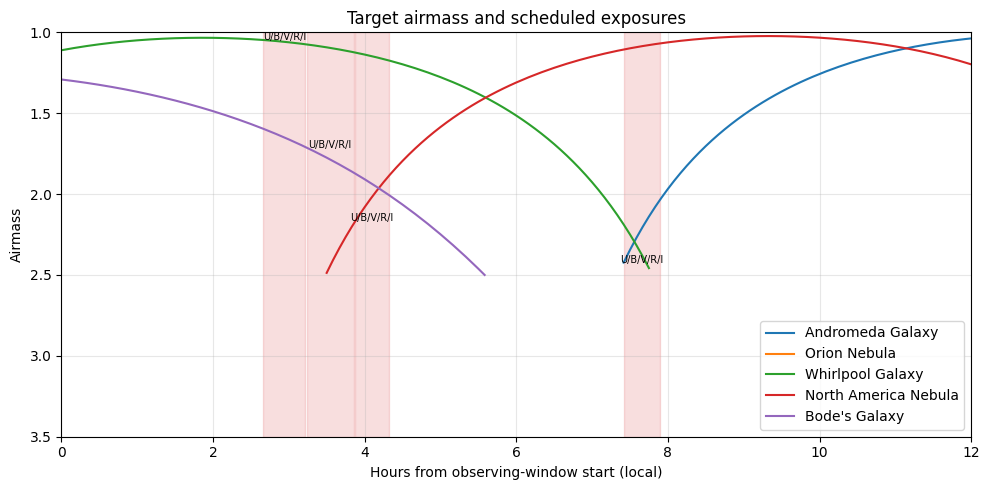

In [4]:
%matplotlib inline
figure = scheduler.plot()
figure